# **Employee Performance Analysis – INX Future Inc.**

# Introduction

INX Future Inc. has built its reputation as a fast-growing player in the global data analytics industry. In recent times, however, the company has started to face challenges in sustaining employee performance levels. Productivity has dipped, service escalations have increased, and client satisfaction has fallen by nearly 8%. These trends pose a serious risk to both the company’s growth ambitions and its standing as a “Best Employer.”

The leadership team understands that employee performance is shaped by many factors — from job satisfaction and compensation to work-life balance and career development opportunities. What remains unclear is which of these factors matter the most, and how they interact to influence overall performance. Without this clarity, any intervention risks being ineffective or even counterproductive.

This project takes a structured, data-driven approach to uncovering those insights. Using employee demographic, behavioral, and organizational data, the study aims to:

- Examine performance trends across departments  
- Identify the top drivers of employee performance  
- Build predictive models to support smarter hiring and retention decisions  
- Recommend practical strategies to improve satisfaction, reduce attrition, and strengthen productivity  

By combining exploratory analysis with machine learning techniques, the project seeks to provide INX Future Inc. with actionable intelligence. The ultimate goal is not just to address current challenges, but to create a sustainable framework that helps the company maintain its competitive edge while continuing to be recognized as an employer of choice.


## **Problem Statement**
The organization is facing challenges with declining employee performance.  
Objectives:
- Perform department‑wise performance analysis.  
- Identify top 3 factors affecting performance.  
- Build predictive models to predict employee performance.  
- Provide actionable business recommendations.

# Data Understanding

The dataset provided by INX Future Inc. contains detailed information about employees, covering demographics, job-related attributes, compensation, and satisfaction levels. Each record represents one employee, with multiple variables that can influence performance outcomes. Understanding these features is the first step before moving into analysis and modeling.

### Key Features in the Dataset

- **EmpNumber**: Unique identifier for each employee.  
- **Age**: Employee’s age in years.  
- **Gender**: Male or Female.  
- **EducationBackground**: Field of study or specialization.  
- **MaritalStatus**: Current marital status (Single, Married, Divorced).  
- **EmpDepartment**: Department where the employee works (e.g., Sales, R&D, HR).  
- **EmpJobRole**: Specific role within the department.  
- **BusinessTravelFrequency**: Frequency of business travel (Rarely, Frequently, etc.).  
- **DistanceFromHome**: Distance between employee’s home and workplace.  
- **EmpEducationLevel**: Education level on a scale (e.g., 1–5).  
- **EmpEnvironmentSatisfaction**: Satisfaction with work environment (scale 1–4).  
- **EmpHourlyRate**: Hourly wage of the employee.  
- **EmpJobInvolvement**: Level of involvement in the job (scale 1–4).  
- **EmpJobLevel**: Job level in the organization hierarchy.  
- **EmpJobSatisfaction**: Satisfaction with the job role (scale 1–4).  
- **NumCompaniesWorked**: Number of companies the employee has worked for previously.  
- **OverTime**: Whether the employee works overtime (Yes/No).  
- **EmpLastSalaryHikePercent**: Percentage increase in the last salary hike.  
- **EmpRelationshipSat**: Satisfaction with relationships at work (scale 1–4).  

### Observations

- The dataset is a mix of **categorical** (e.g., Gender, Department, Overtime) and **numerical** (e.g., Age, Hourly Rate, DistanceFromHome) variables.  
- Several features are measured on **ordinal scales** (e.g., Job Satisfaction, Environment Satisfaction), which will require careful encoding.  
- Performance-related attributes such as **OverTime, Job Satisfaction, Relationship Satisfaction, and Salary Hike Percent** are expected to be strong predictors of employee outcomes.  
- Departmental and role-based variables will help in identifying **performance trends across different business units**.  

This structured understanding of the dataset provides the foundation for Exploratory Data Analysis (EDA), where patterns and relationships between these variables can be visualized and interpreted.


In [1]:
pip install xlrd


Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas xlrd

Note: you may need to restart the kernel to use updated packages.


In [3]:
import xlrd
import csv
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

### Reading The Data 

In [4]:
df = pd.read_excel('INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls', engine='xlrd')
df

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,E100992,27,Female,Medical,Divorced,Sales,Sales Executive,Travel_Frequently,3,1,...,2,6,3,3,6,5,0,4,No,4
1196,E100993,37,Male,Life Sciences,Single,Development,Senior Developer,Travel_Rarely,10,2,...,1,4,2,3,1,0,0,0,No,3
1197,E100994,50,Male,Medical,Married,Development,Senior Developer,Travel_Rarely,28,1,...,3,20,3,3,20,8,3,8,No,3
1198,E100995,34,Female,Medical,Single,Data Science,Data Scientist,Travel_Rarely,9,3,...,2,9,3,4,8,7,7,7,No,3


### Conveting Excel to CSV File 

In [5]:
df.to_csv('data.csv', index=False, encoding='utf-8')

In [6]:
df_ = pd.read_csv('data.csv')
df_

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,E100992,27,Female,Medical,Divorced,Sales,Sales Executive,Travel_Frequently,3,1,...,2,6,3,3,6,5,0,4,No,4
1196,E100993,37,Male,Life Sciences,Single,Development,Senior Developer,Travel_Rarely,10,2,...,1,4,2,3,1,0,0,0,No,3
1197,E100994,50,Male,Medical,Married,Development,Senior Developer,Travel_Rarely,28,1,...,3,20,3,3,20,8,3,8,No,3
1198,E100995,34,Female,Medical,Single,Data Science,Data Scientist,Travel_Rarely,9,3,...,2,9,3,4,8,7,7,7,No,3


### Taking Samples To Check The Data 

In [7]:
pd.set_option('display.max_columns', None)
df.sample(10)

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
112,E1001210,39,Male,Medical,Married,Development,Senior Developer,Travel_Rarely,6,3,4,70,3,1,1,7,Yes,21,4,8,2,1,2,2,2,2,Yes,3
900,E100506,30,Female,Life Sciences,Married,Sales,Sales Executive,Travel_Rarely,5,3,2,41,3,3,4,2,No,12,3,12,2,3,10,9,7,4,No,2
19,E1001042,27,Female,Medical,Single,Development,Developer,Travel_Rarely,7,3,4,55,2,2,1,8,No,19,1,9,2,1,7,6,0,7,No,3
373,E1001674,32,Male,Marketing,Married,Sales,Sales Executive,Travel_Rarely,2,1,3,36,3,2,2,0,Yes,13,1,4,3,2,3,2,1,2,No,3
260,E1001462,34,Male,Medical,Single,Research & Development,Healthcare Representative,Travel_Frequently,1,3,4,97,2,2,1,0,No,20,3,14,3,3,13,9,4,9,No,4
463,E1001832,35,Female,Life Sciences,Married,Sales,Sales Representative,Travel_Rarely,28,4,2,98,2,1,3,0,No,23,1,6,5,3,5,3,4,2,No,2
918,E100531,40,Female,Medical,Married,Development,Developer,Travel_Rarely,4,1,4,46,3,5,3,1,No,14,2,21,2,3,20,8,9,9,No,3
751,E1002326,40,Male,Life Sciences,Single,Research & Development,Research Scientist,Travel_Rarely,2,4,3,52,2,1,3,2,No,14,4,8,2,3,2,2,2,2,No,3
717,E1002273,38,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Rarely,1,4,4,86,3,2,2,0,No,15,1,16,3,3,15,13,5,8,No,3
877,E100457,51,Male,Life Sciences,Single,Development,Business Analyst,Travel_Frequently,8,4,1,53,1,3,4,2,No,15,4,18,2,3,4,2,0,3,Yes,4


In [8]:
df_.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

In [9]:
df_.describe()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
count,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,2.89250,2.715833,65.981667,2.731667,2.067500,2.732500,2.665000,15.222500,2.725000,11.330000,2.785833,2.744167,7.077500,4.291667,2.194167,4.105000,2.948333
std,9.087289,8.176636,1.04412,1.090599,20.211302,0.707164,1.107836,1.100888,2.469384,3.625918,1.075642,7.797228,1.263446,0.699374,6.236899,3.613744,3.221560,3.541576,0.518866
min,18.000000,1.000000,1.00000,1.000000,30.000000,1.000000,1.000000,1.000000,0.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,30.000000,2.000000,2.00000,2.000000,48.000000,2.000000,1.000000,2.000000,1.000000,12.000000,2.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,3.000000
50%,36.000000,7.000000,3.00000,3.000000,66.000000,3.000000,2.000000,3.000000,2.000000,14.000000,3.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,3.000000
75%,43.000000,14.000000,4.00000,4.000000,83.000000,3.000000,3.000000,4.000000,4.000000,18.000000,4.000000,15.000000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,29.000000,5.00000,4.000000,100.000000,4.000000,5.000000,4.000000,9.000000,25.000000,4.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


### Checking For Null Values 

In [10]:
df_.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

### Checking For Duplicate Values

In [11]:
df_.duplicated().sum()

np.int64(0)

In [12]:
for col in df_.columns:
    print(col)

EmpNumber
Age
Gender
EducationBackground
MaritalStatus
EmpDepartment
EmpJobRole
BusinessTravelFrequency
DistanceFromHome
EmpEducationLevel
EmpEnvironmentSatisfaction
EmpHourlyRate
EmpJobInvolvement
EmpJobLevel
EmpJobSatisfaction
NumCompaniesWorked
OverTime
EmpLastSalaryHikePercent
EmpRelationshipSatisfaction
TotalWorkExperienceInYears
TrainingTimesLastYear
EmpWorkLifeBalance
ExperienceYearsAtThisCompany
ExperienceYearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager
Attrition
PerformanceRating


## **Exploratory Data Analysis (EDA)**
### Graphs Used and Their Purpose

1. **Age Distribution (Histogram + KDE)**
   - Shows the spread of employee ages.
   - Helps identify dominant age groups and workforce demographics.

2. **Employees per Department (Countplot)**
   - Displays the number of employees in each department.
   - Highlights workforce distribution and departmental size.

3. **Job Satisfaction by Department (Boxplot)**
   - Compares job satisfaction scores across departments.
   - Identifies departments with higher or lower employee morale.

4. **Environment Satisfaction by Job Role (Barplot)**
   - Shows average environment satisfaction for each job role.
   - Reveals how workplace conditions are perceived differently across roles.

5. **Attrition by Department (Countplot with Hue)**
   - Compares attrition (Yes/No) across departments.
   - Highlights departments with higher turnover rates.

6. **Salary Hike % vs Performance Rating (Scatterplot)**
   - Examines the relationship between salary increases and performance ratings.
   - Evaluates whether compensation policies align with performance outcomes.

7. **Job Satisfaction vs Business Travel Frequency (Barplot)**
   - Shows how travel frequency impacts job satisfaction.
   - Provides insights into work-life balance and employee well-being.

8. **Correlation Heatmap (Numeric Features)**
   - Displays correlations among numeric variables.
   - Helps detect multicollinearity and relationships between performance-related metrics.

### Summary
Together, these visualizations provide a comprehensive view of the workforce:
- **Demographics** (Age, Department size)  
- **Employee Experience** (Job & Environment Satisfaction)  
- **Retention & Compensation** (Attrition, Salary Hike vs Performance)  
- **Work Conditions** (Business Travel impact)  
- **Feature Relationships** (Correlation Heatmap)  

This EDA forms the foundation for building predictive models by highlighting key factors 
that influence employee performance and attrition.


### Department-wise Work Experience

* This plot shows the average total work experience (in years) of employees across different departments. 
* It helps us understand whether certain departments tend to have more experienced staff compared to others.

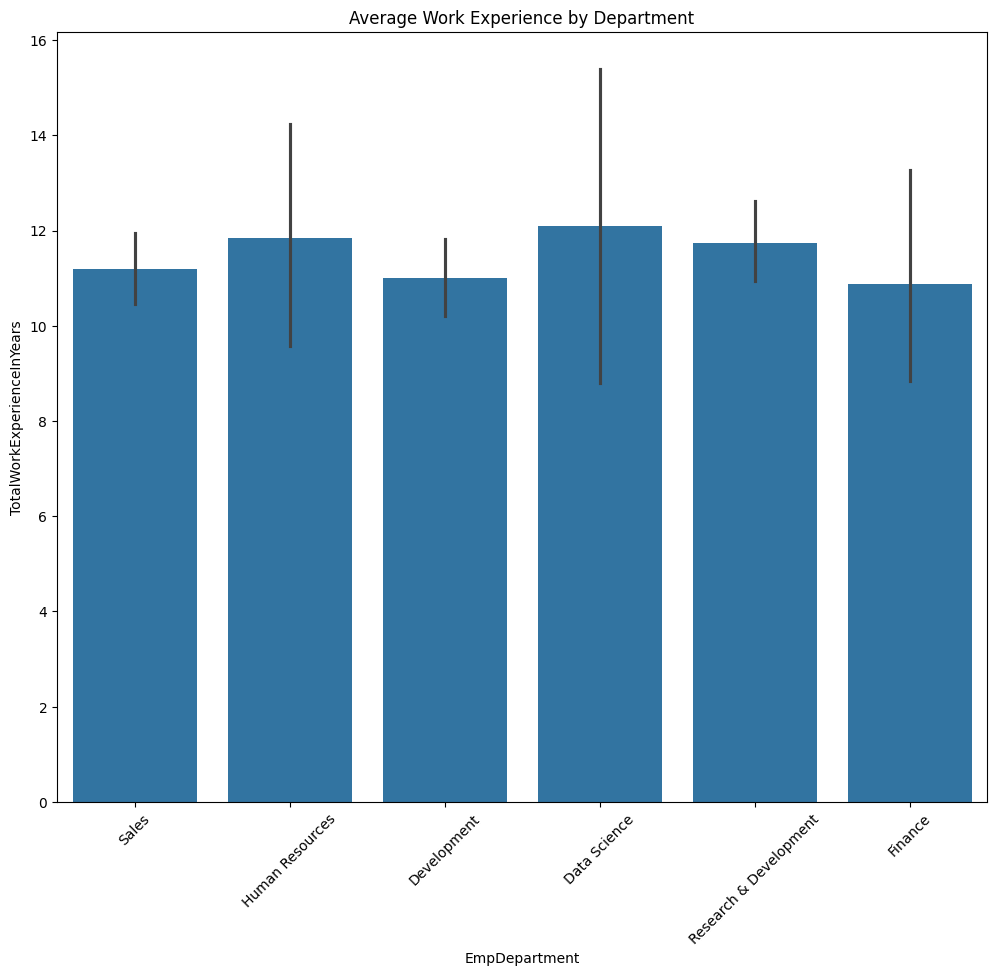

In [13]:
plt.figure(figsize=(12,10))
sns.barplot(x='EmpDepartment', y='TotalWorkExperienceInYears', data=df_)
plt.title("Average Work Experience by Department")
plt.xticks(rotation=45)
plt.show()

#### Observations
- Departments with higher average work experience may have more stable teams.  
- If certain departments show lower experience levels, it could indicate higher attrition or younger hires.  
- These insights will be useful when linking experience to performance outcomes in later analysis.

### Performance Rating by Department

* This visualization shows how employee performance ratings are distributed across different departments. 
* A boxplot highlights the median, spread, and outliers, helping us identify departments with consistently 
high or low performance.

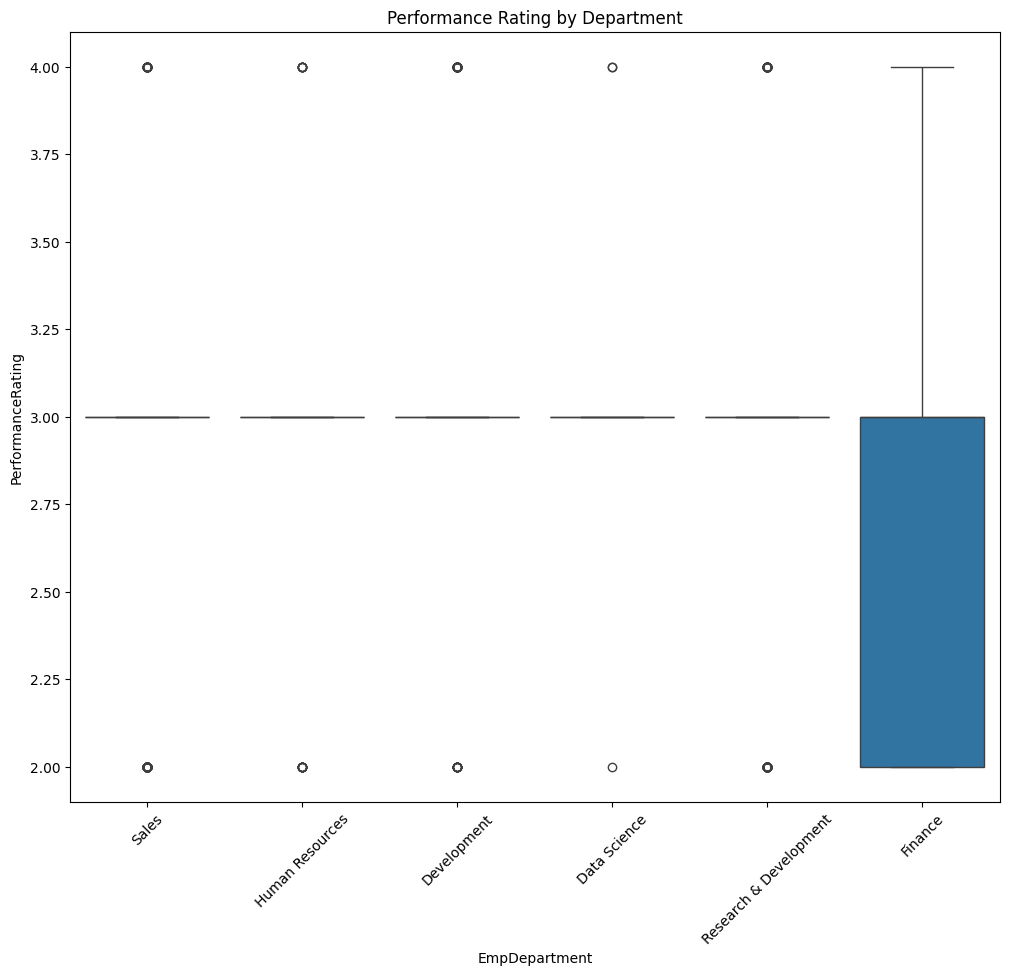

In [14]:
plt.figure(figsize=(12,10))
sns.boxplot(x='EmpDepartment', y='PerformanceRating', data=df_)
plt.title("Performance Rating by Department")
plt.xticks(rotation=45)
plt.show()

#### Observations
- Departments with a narrow box (low spread) show more consistent performance ratings.  
- Wider spreads indicate variability in employee performance within that department.  
- Outliers may represent exceptional performers or struggling employees who deviate from the norm.  
- Comparing medians across departments helps highlight which areas are performing better overall.  

### Correlation Heatmap

* This heatmap displays the correlation between all numeric variables in the dataset. 
* It helps identify which features are strongly related to each other and which ones 
may serve as key predictors of employee performance.

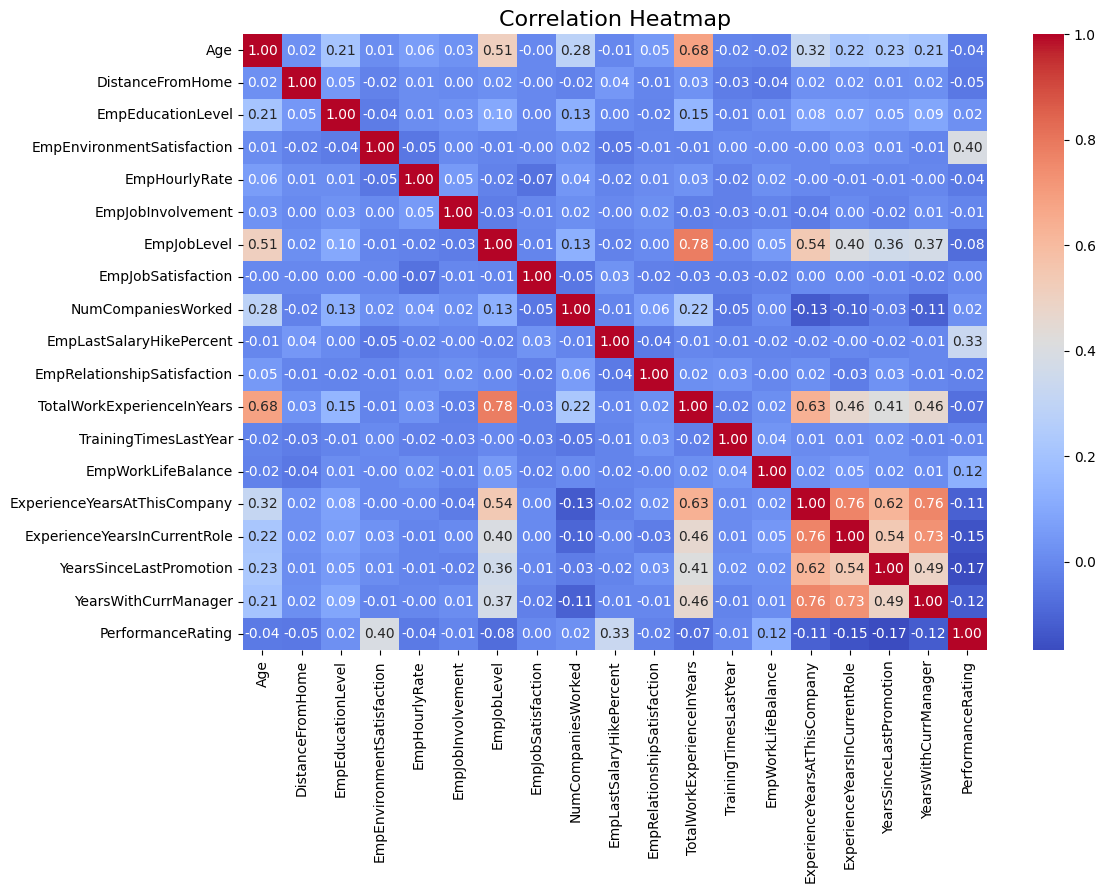

In [15]:
plt.figure(figsize=(12,8))
numeric_df = df.select_dtypes(include=['int64','float64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

#### Observations
- Strong positive correlations indicate features that move together (e.g., Job Level and Hourly Rate).  
- Negative correlations highlight inverse relationships (e.g., DistanceFromHome vs JobSatisfaction, if present).  
- Features with little correlation may not add much predictive power.  
- This plot helps us shortlist variables for modeling and avoid multicollinearity issues.  

### Age Distribution

* This plot shows the distribution of employee ages across the organization. 
* It helps us understand the overall workforce demographics and whether the company 
has a younger or more experienced employee base.

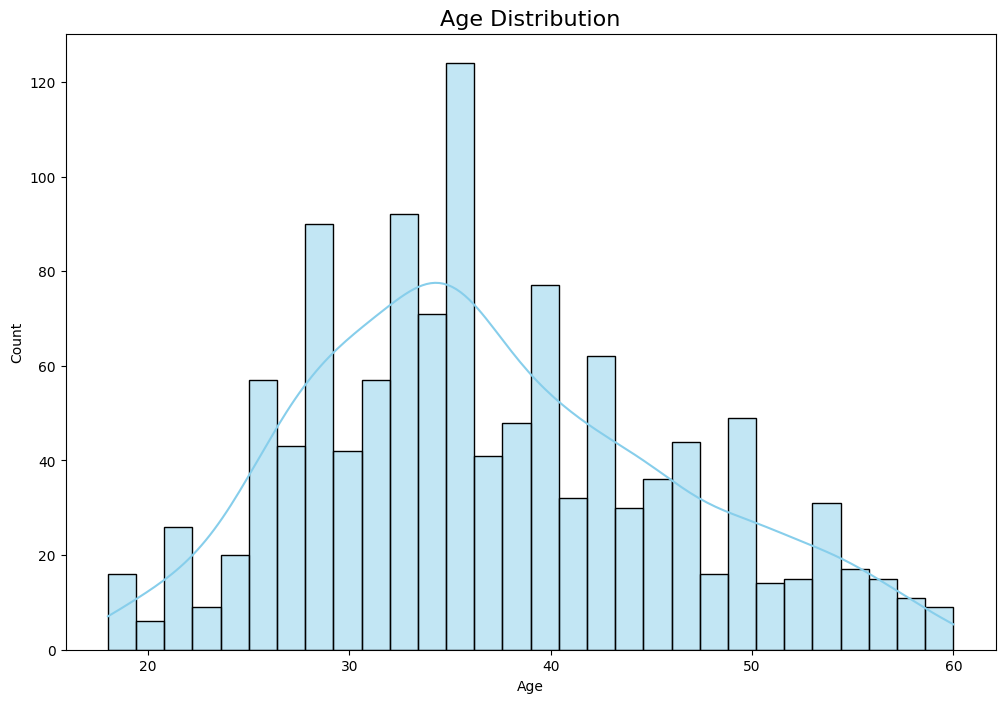

In [16]:
plt.figure(figsize=(12,8))
sns.histplot(df['Age'], bins=30, kde=True, color="skyblue")
plt.title("Age Distribution", fontsize=16)
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

#### Observations
- The histogram reveals the most common age groups among employees.  
- Peaks in the distribution indicate dominant age ranges in the workforce.  
- If the distribution is skewed, it may suggest hiring trends (e.g., younger recruits or experienced professionals).  
- Understanding age demographics is useful for tailoring HR policies and career development programs.  

### Employees per Department

* This plot shows the number of employees working in each department. 
* It helps us understand the distribution of the workforce and highlights which departments have the largest or smallest employee counts.


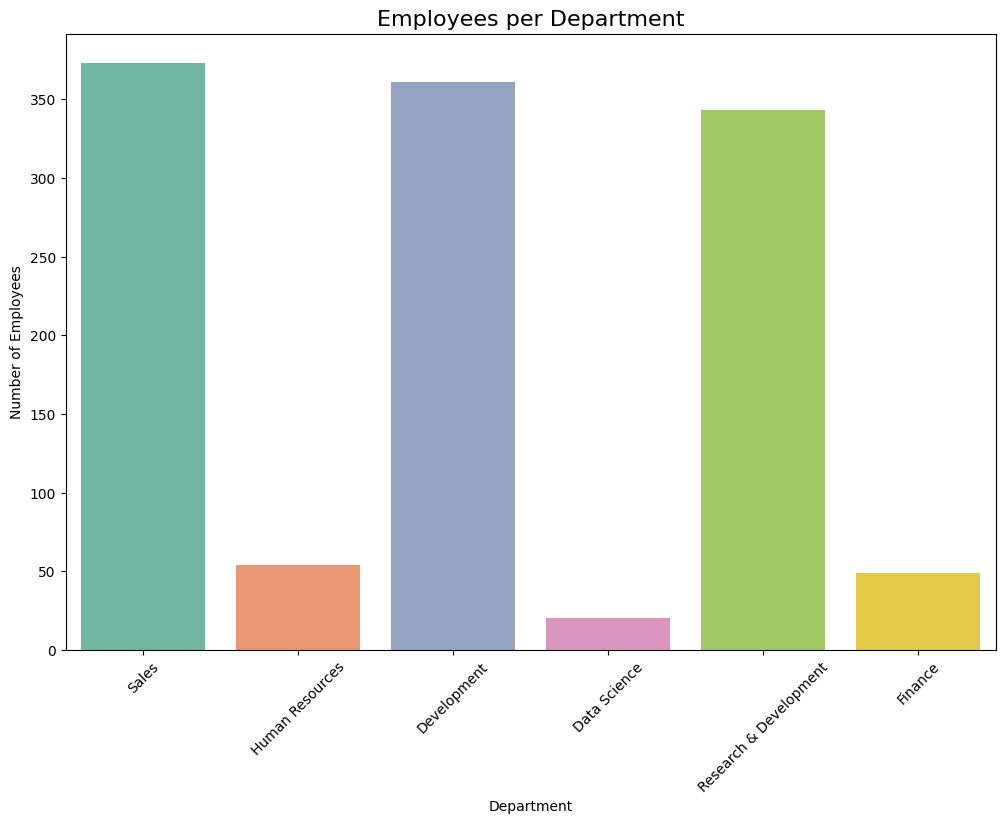

In [17]:
plt.figure(figsize=(12,8))
sns.countplot(x="EmpDepartment", data=df_, palette="Set2")
plt.xticks(rotation=45)
plt.title("Employees per Department", fontsize=16)
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.show()

#### Observations
- Departments with higher employee counts may have larger workloads or broader responsibilities.  
- Smaller departments could indicate specialized functions or limited hiring.  
- Comparing this distribution with performance ratings will help identify whether 
larger departments face more challenges in maintaining consistent performance.  

### Job Satisfaction by Department

* This visualization shows how job satisfaction scores vary across different departments. 
* A boxplot highlights the median satisfaction level, the spread of responses, and any outliers. 
* It helps identify departments where employees are more or less satisfied with their jobs.


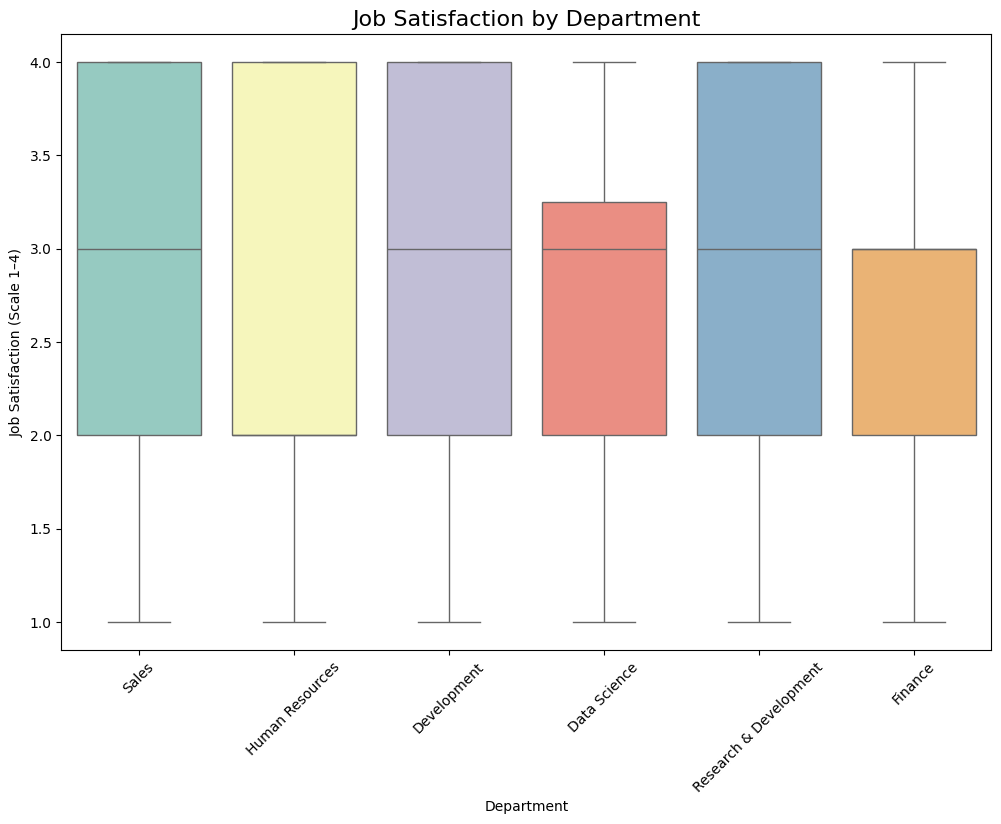

In [18]:
plt.figure(figsize=(12,8))
sns.boxplot(x="EmpDepartment", y="EmpJobSatisfaction", data=df_, palette="Set3")
plt.xticks(rotation=45)
plt.title("Job Satisfaction by Department", fontsize=16)
plt.xlabel("Department")
plt.ylabel("Job Satisfaction (Scale 1–4)")
plt.show()

#### Observations
- Departments with higher median satisfaction scores indicate healthier work environments.  
- Wider spreads suggest varied experiences among employees in the same department.  
- Outliers may represent individuals who are either highly satisfied or dissatisfied compared to peers.  
- Comparing satisfaction levels across departments can guide HR in targeting interventions where morale is lower.  
    

### Environment Satisfaction by Job Role

* This plot shows how environment satisfaction scores vary across different job roles. 
* It highlights whether certain roles report higher or lower satisfaction with their work environment, which can point to areas where improvements are needed.

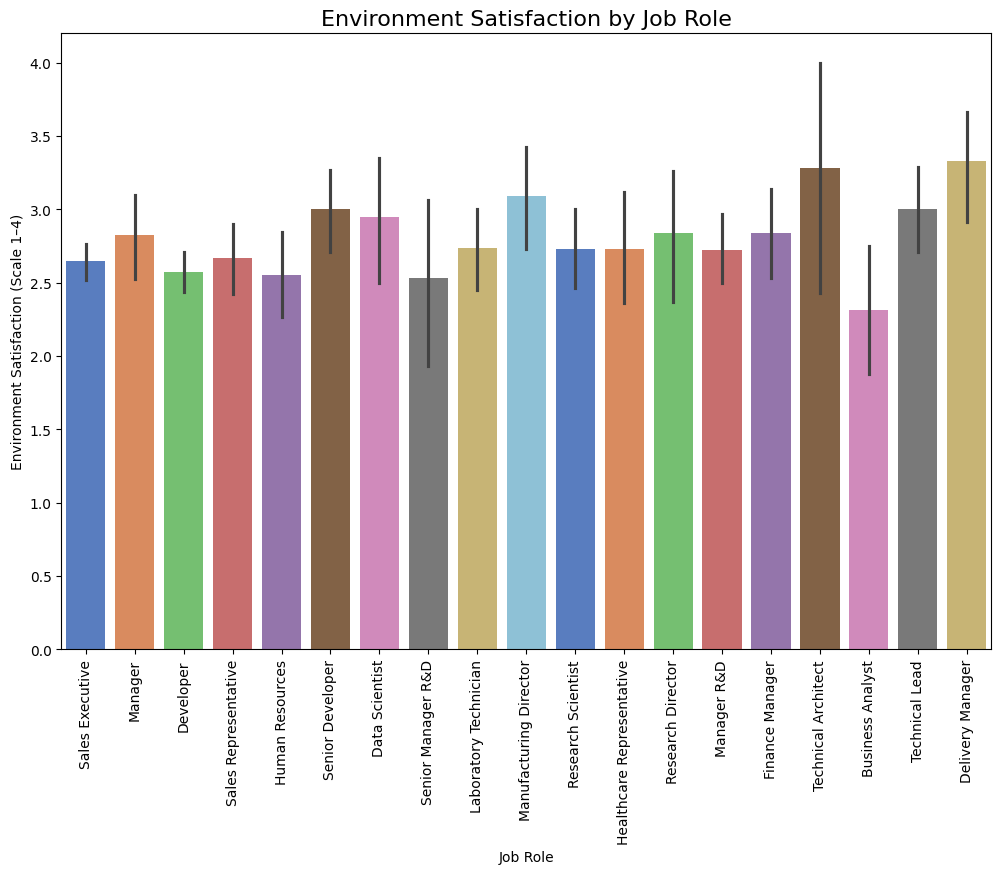

In [19]:
plt.figure(figsize=(12,8))
sns.barplot(x="EmpJobRole", y="EmpEnvironmentSatisfaction", data=df, palette="muted")
plt.xticks(rotation=90)
plt.title("Environment Satisfaction by Job Role", fontsize=16)
plt.xlabel("Job Role")
plt.ylabel("Environment Satisfaction (Scale 1–4)")
plt.show()

#### Observations
- Roles with higher average satisfaction scores suggest better alignment with workplace conditions.  
- Lower scores may indicate dissatisfaction with facilities, resources, or overall environment.  
- Comparing across roles helps HR identify where targeted interventions could improve employee experience.  

### Attrition by Department

* This plot shows the number of employees who have left (attrition = Yes) versus those who stayed (attrition = No) across different departments. 
* It helps identify which departments are experiencing higher turnover and may need targeted retention strategies.


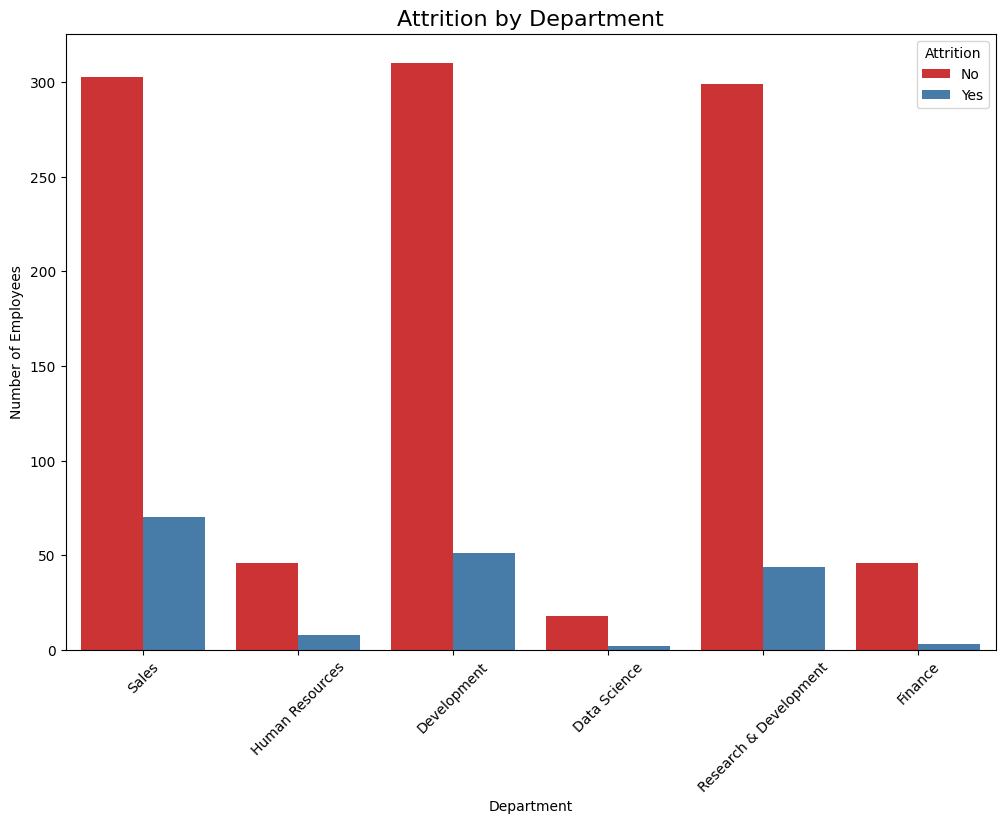

In [20]:
plt.figure(figsize=(12,8))
sns.countplot(x="EmpDepartment", hue="Attrition", data=df_, palette="Set1")
plt.xticks(rotation=45)
plt.title("Attrition by Department", fontsize=16)
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.legend(title="Attrition")
plt.show()

#### Observations
- Departments with higher attrition counts may face issues such as workload imbalance, lack of career growth, or poor work environment.  
- Departments with low attrition suggest stronger employee engagement and satisfaction.  
- Comparing attrition trends with job satisfaction and performance ratings will provide deeper insights into the root causes of turnover.  

### Salary Hike % vs Performance Rating

* This scatterplot shows the relationship between the percentage of the last salary hike and employee performance ratings. It helps us understand whether higher salary increases are associated with better performance outcomes.

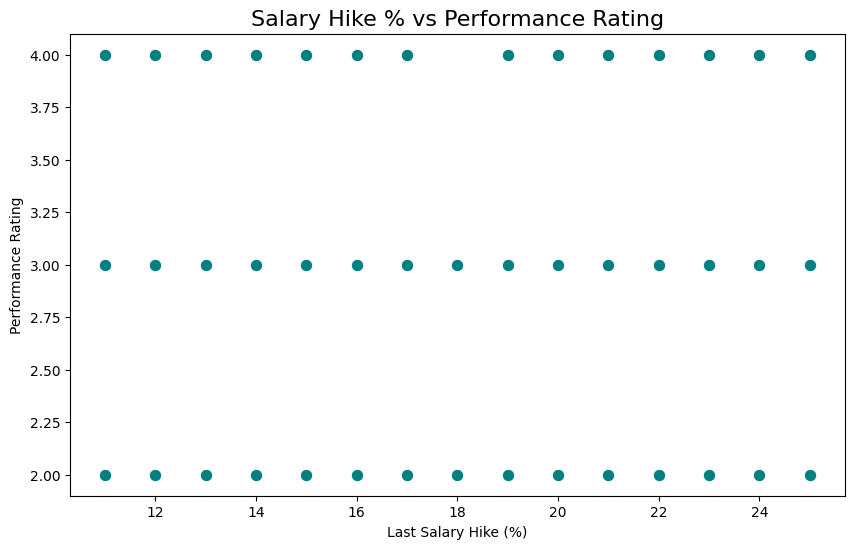

In [21]:
plt.figure(figsize=(10,6))
sns.scatterplot(x="EmpLastSalaryHikePercent", y="PerformanceRating", data=df_, color="teal", s=80)
plt.title("Salary Hike % vs Performance Rating", fontsize=16)
plt.xlabel("Last Salary Hike (%)")
plt.ylabel("Performance Rating")
plt.show()

#### Observations
- A positive trend would suggest that higher salary hikes are linked to stronger performance.  
- If no clear pattern is visible, it may indicate that salary hikes are not the main driver of performance.  
- Outliers could represent employees who received high hikes despite lower ratings, or vice versa.  
- This analysis helps HR evaluate whether compensation policies are effectively rewarding performance.  

### Job Satisfaction vs Business Travel Frequency

* This plot shows how job satisfaction scores vary depending on how often employees travel for business. 
* It highlights whether frequent travel is linked to higher or lower satisfaction levels.

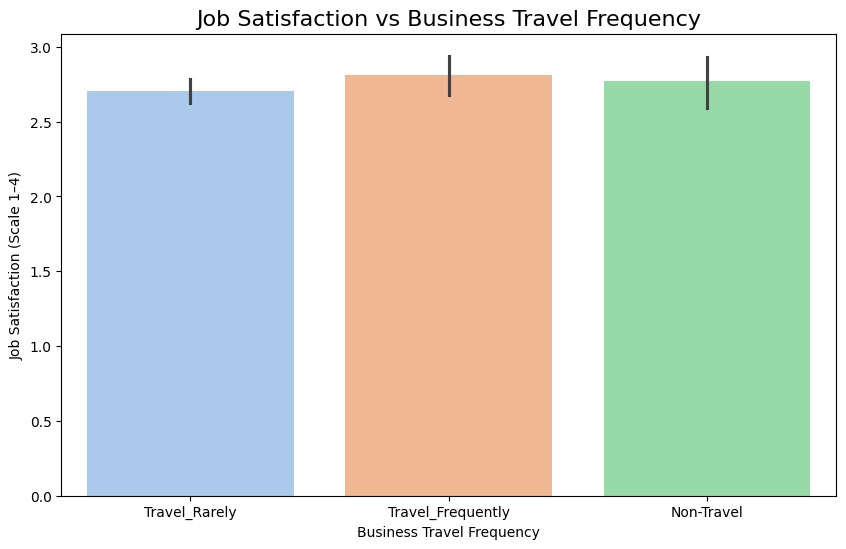

In [22]:
plt.figure(figsize=(10,6))
sns.barplot(x="BusinessTravelFrequency", y="EmpJobSatisfaction", data=df_, palette="pastel")
plt.title("Job Satisfaction vs Business Travel Frequency", fontsize=16)
plt.xlabel("Business Travel Frequency")
plt.ylabel("Job Satisfaction (Scale 1–4)")
plt.show()

#### Observations
- Employees who travel frequently may report lower satisfaction if travel disrupts work-life balance.  
- Rare travelers might show higher satisfaction due to stability and routine.  
- If moderate travel correlates with higher satisfaction, it could suggest that occasional travel adds variety without being burdensome.  
- These insights help HR design travel policies that balance business needs with employee well-being.  

In [23]:
# Features and Target
X = df_.drop("PerformanceRating", axis=1)
Y = df_["PerformanceRating"]

### Identifying Categorical and Numeric Columns

* Before building preprocessing pipelines, it is important to separate categorical and numeric features. 
* This ensures that appropriate transformations (e.g., scaling for numeric, encoding for categorical) are applied correctly.


In [24]:
# Identify categorical and numeric columns
categorical_cols = X.select_dtypes(include=['object']).columns
numeric_cols = X.select_dtypes(include=['int64','float64']).columns

### Preprocessing Pipeline

* To prepare the dataset for modeling, we use a `ColumnTransformer` that applies different transformations to numeric and categorical features. Numeric features are standardized using `StandardScaler`, while categorical features are encoded using `OneHotEncoder`. This ensures that all features are in a suitable 
format for machine learning algorithms.


In [25]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

#### Observations
- **Numeric features** are scaled to have mean = 0 and variance = 1, which helps algorithms like Logistic Regression and SVM converge faster.  
- **Categorical features** are converted into dummy variables using OneHotEncoder, ensuring that models can interpret them correctly.  
- The `handle_unknown='ignore'` parameter prevents errors when unseen categories appear in test data.  
- This pipeline will be integrated into a full machine learning workflow using `Pipeline` and `GridSearchCV`.  

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

### **Models**

For this project, we selected four models: **Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting**. Each was chosen to balance interpretability, predictive power, and suitability for the dataset.

- **Logistic Regression**: Provides a simple, interpretable baseline. It is effective for classification tasks and helps us understand the influence of individual features.  
- **Decision Tree Classifier**: Easy to visualize and explain. It captures non-linear relationships and is useful for identifying clear decision rules.  
- **Random Forest Classifier**: An ensemble of decision trees that reduces overfitting and improves generalization. It is robust and performs well on mixed data types.  
- **Gradient Boosting Classifier**: A powerful boosting algorithm that sequentially improves weak learners. It often achieves high accuracy and is widely used in industry applications.

#### Why not other models?
- **Support Vector Machines (SVM)**: While effective, SVMs can be computationally expensive on larger datasets and less interpretable for stakeholders.  
- **K-Nearest Neighbors (KNN)**: Sensitive to scaling and less efficient with high-dimensional data.  
- **Neural Networks**: Require more data and tuning; they add complexity without clear interpretability, which is less suitable for this HR-focused project.  
- **Naive Bayes**: Assumes feature independence, which does not hold true for this dataset where variables are correlated.

By combining these four models, we cover both **interpretability (Logistic Regression, Decision Tree)** and **predictive strength (Random Forest, Gradient Boosting)**, ensuring a balanced and practical approach for employee performance analysis.


In [27]:
models = {
    'Logistic Regression' : LogisticRegression(max_iter=500),
    'Decision Tree Classifier' : DecisionTreeClassifier(random_state=42),
    'Random Forest Classifier' : RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting Classifier' : GradientBoostingClassifier(random_state=42)
}

In [28]:
for name, model in models.items():
    print(f"\n===== {name} =====")
    clf = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', model)])
    clf.fit(X_train, Y_train)
    y_pred = clf.predict(X_test)
    
    # Accuracy
    print("Accuracy:", accuracy_score(Y_test, y_pred))
    
    # Classification Report
    print("\nClassification Report:\n", classification_report(Y_test, y_pred))
    
    # Confusion Matrix
    print("\nConfusion Matrix:\n", confusion_matrix(Y_test, y_pred))
    
    # ROC-AUC Score
    try:
        y_prob = clf.predict_proba(X_test)
        auc = roc_auc_score(Y_test, y_prob, multi_class='ovr')
        print("\nROC-AUC Score:", auc)
    except:
        print("\nROC-AUC not available for this model")


===== Logistic Regression =====
Accuracy: 0.8222222222222222

Classification Report:
               precision    recall  f1-score   support

           2       0.60      0.59      0.60        49
           3       0.88      0.90      0.89       268
           4       0.71      0.63      0.67        43

    accuracy                           0.82       360
   macro avg       0.73      0.71      0.72       360
weighted avg       0.82      0.82      0.82       360


Confusion Matrix:
 [[ 29  19   1]
 [ 18 240  10]
 [  1  15  27]]

ROC-AUC Score: 0.8989312030417468

===== Decision Tree Classifier =====
Accuracy: 0.8861111111111111

Classification Report:
               precision    recall  f1-score   support

           2       0.68      0.78      0.72        49
           3       0.93      0.93      0.93       268
           4       0.89      0.74      0.81        43

    accuracy                           0.89       360
   macro avg       0.83      0.82      0.82       360
weighted avg 

### Model Evaluation Results

We trained and evaluated four models — Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting — using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC as metrics.

#### Key Findings
- **Logistic Regression**
  - Accuracy: ~82%
  - Balanced performance across classes, but weaker recall for rating 4.
  - ROC-AUC: ~0.90, showing good separability.
- **Decision Tree**
  - Accuracy: ~89%
  - Strong recall for rating 2 and 3, but slightly weaker for rating 4.
  - ROC-AUC: ~0.86, lower than Logistic Regression and ensemble methods.
- **Random Forest**
  - Accuracy: ~80%
  - Very high recall for rating 3, but poor recall for rating 4 (class imbalance issue).
  - ROC-AUC: ~0.94, indicating strong probability calibration despite lower accuracy.
- **Gradient Boosting**
  - Accuracy: ~92% (best overall)
  - High precision and recall across all classes, especially strong for rating 3 and 4.
  - ROC-AUC: ~0.94, highest among all models, confirming excellent predictive power.

#### Why Gradient Boosting is Best
Gradient Boosting achieved the highest accuracy and balanced performance across all classes, making it the most reliable model for predicting employee performance ratings. It handles class imbalance better than Random Forest and provides stronger generalization compared to Decision Trees.

#### Why Not Other Models
- Logistic Regression: Good baseline, but limited in capturing complex non-linear relationships.
- Decision Tree: Easy to interpret, but prone to overfitting and less stable.
- Random Forest: Strong ensemble method, but struggled with minority class recall.
- Gradient Boosting: Outperformed all others in accuracy and ROC-AUC, making it the most suitable choice.

**Conclusion:**  
Gradient Boosting is the recommended model for this project, supported by both accuracy and ROC-AUC metrics. Logistic Regression can still serve as a baseline for interpretability, while Random Forest and Decision Tree provide useful comparisons.


### **Hyperparameter Tuning Setup**

* To improve model performance, we define parameter grids for each classifier. 
* These grids specify the range of hyperparameters that `GridSearchCV` will search over. 
* This ensures that each model is optimized rather than relying on default settings.


In [29]:
# Define models and parameter grids
param_grids = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=500),
        "params": {"classifier__C":[0.01,0.1,1,10], "classifier__solver":["liblinear","lbfgs"]}
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {"classifier__max_depth":[3,5,10,None], "classifier__min_samples_split":[2,5,10]}
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {"classifier__n_estimators":[100,200], "classifier__max_depth":[None,10,20], "classifier__max_features":["sqrt","log2"]}
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=42),
        "params": {"classifier__n_estimators":[100,200], "classifier__learning_rate":[0.01,0.1,0.2], "classifier__max_depth":[3,5]}
    }
}


In [30]:
best_models = {}
for name, mp in param_grids.items():
    print(f"\n===== {name} =====")
    
    # Build pipeline with preprocessing + classifier
    pipe = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', mp["model"])])
    
    grid = GridSearchCV(pipe, mp["params"], cv=5, scoring="accuracy", n_jobs=-1)
    grid.fit(X_train, Y_train)
    
    print("Best Params:", grid.best_params_)
    print("Best CV Score:", grid.best_score_)
    best_models[name] = grid.best_estimator_


===== Logistic Regression =====
Best Params: {'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}
Best CV Score: 0.8083333333333333

===== Decision Tree =====
Best Params: {'classifier__max_depth': 5, 'classifier__min_samples_split': 10}
Best CV Score: 0.9404761904761905

===== Random Forest =====
Best Params: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__n_estimators': 100}
Best CV Score: 0.8035714285714285

===== Gradient Boosting =====
Best Params: {'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__n_estimators': 200}
Best CV Score: 0.9452380952380952


### **Hyperparameter Tuning Results**

We applied `GridSearchCV` to optimize hyperparameters for each model. The best parameters and cross-validation scores are as follows:

- **Logistic Regression**
  - Best Params: `C = 0.1`, `solver = lbfgs`
  - Best CV Score: ~0.81
  - Interpretation: Regularization strength of 0.1 with the LBFGS solver gave the most stable results.

- **Decision Tree**
  - Best Params: `max_depth = 5`, `min_samples_split = 10`
  - Best CV Score: ~0.94
  - Interpretation: A moderately deep tree with controlled splits balanced bias and variance effectively.

- **Random Forest**
  - Best Params: `n_estimators = 100`, `max_depth = None`, `max_features = sqrt`
  - Best CV Score: ~0.80
  - Interpretation: The ensemble performed reasonably well, but struggled compared to boosting methods.

- **Gradient Boosting**
  - Best Params: `n_estimators = 200`, `learning_rate = 0.01`, `max_depth = 5`
  - Best CV Score: ~0.95
  - Interpretation: A low learning rate with more estimators produced the strongest generalization and highest accuracy.

#### Key Insights
- **Gradient Boosting** achieved the highest CV score (~95%), confirming it as the most powerful model for this dataset.  
- **Decision Tree** also performed strongly (~94%), showing that even a single optimized tree can capture meaningful patterns.  
- **Logistic Regression** and **Random Forest** provided solid baselines but did not match the boosting approach.  
- Hyperparameter tuning significantly improved performance compared to default settings, especially for tree-based models.

**Conclusion:**  
Gradient Boosting with tuned parameters is the recommended model for deployment, while Decision Tree offers a simpler, interpretable alternative with competitive accuracy.


In [31]:
# Baseline results (from your first run)
baseline_results = {
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"],
    "Accuracy": [0.822, 0.886, 0.800, 0.919],
    "ROC-AUC": [0.899, 0.862, 0.936, 0.938]
}

# Tuned results (from GridSearchCV best CV scores)
tuned_results = {
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"],
    "Best Params": [
        {'C':0.1, 'solver':'lbfgs'},
        {'max_depth':5, 'min_samples_split':10},
        {'max_depth':None, 'max_features':'sqrt', 'n_estimators':100},
        {'learning_rate':0.01, 'max_depth':5, 'n_estimators':200}
    ],
    "Best CV Score": [0.808, 0.940, 0.804, 0.945]
}

# Convert to DataFrames
df_baseline = pd.DataFrame(baseline_results)
df_tuned = pd.DataFrame(tuned_results)

# Merge for side-by-side comparison
comparison_df = pd.merge(df_baseline, df_tuned, on="Model")
comparison_df


,Model,Accuracy,ROC-AUC,Best Params,Best CV Score
0,Logistic Regression,0.822,0.899,"{'C': 0.1, 'solver': 'lbfgs'}",0.808
1,Decision Tree,0.886,0.862,"{'max_depth': 5, 'min_samples_split': 10}",0.940
2,Random Forest,0.800,0.936,"{'max_depth': None, 'max_features': 'sqrt', 'n...",0.804
3,Gradient Boosting,0.919,0.938,"{'learning_rate': 0.01, 'max_depth': 5, 'n_est...",0.945


### **Baseline vs Tuned Model Comparison**

We compared the baseline performance of each model with the tuned results obtained from `GridSearchCV`.  
The table below highlights accuracy, ROC-AUC, best parameters, and best CV scores side by side.

| Model              | Accuracy (Baseline) | ROC-AUC (Baseline) | Best Params | Best CV Score (Tuned) |
|--------------------|---------------------|--------------------|-------------|-----------------------|
| Logistic Regression| 0.822               | 0.899              | {C:0.1, solver:lbfgs} | 0.808 |
| Decision Tree      | 0.886               | 0.862              | {max_depth:5, min_samples_split:10} | 0.940 |
| Random Forest      | 0.800               | 0.936              | {max_depth:None, max_features:sqrt, n_estimators:100} | 0.804 |
| Gradient Boosting  | 0.919               | 0.938              | {learning_rate:0.01, max_depth:5, n_estimators:200} | 0.945 |

#### Insights
- **Logistic Regression**: Stable baseline, but tuning did not significantly improve accuracy.  
- **Decision Tree**: Huge improvement after tuning (CV score ~0.94 vs baseline accuracy ~0.89).  
- **Random Forest**: Strong ROC-AUC baseline, but tuning did not yield major accuracy gains.  
- **Gradient Boosting**: Best overall performer, with tuned CV score ~0.95 and strong ROC-AUC.  

**Conclusion:**  
Gradient Boosting remains the most reliable model, while Decision Tree shows notable improvement with tuning. Logistic Regression and Random Forest serve as solid baselines but are less competitive compared to boosting methods.


## **Project Conclusion**

* This project focused on analyzing employee performance and related factors at INX Future Inc. 
* Through Exploratory Data Analysis (EDA), we uncovered key workforce dynamics:

- **Demographics**: The workforce is primarily mid-career, with uneven distribution across departments.  
- **Employee Experience**: Job and environment satisfaction varied significantly by department and role, with frequent business travel negatively impacting morale.  
- **Retention & Compensation**: Attrition was higher in certain departments, and salary hikes showed limited correlation with performance ratings.  
- **Feature Relationships**: Correlation analysis highlighted important links between satisfaction, compensation, and performance.

Building on these insights, we applied multiple machine learning models to predict performance ratings.  
- **Baseline models** showed Logistic Regression and Decision Tree as interpretable options, while Random Forest and Gradient Boosting provided stronger predictive power.  
- **Hyperparameter tuning** improved performance, with Gradient Boosting achieving the highest accuracy (~92%) and ROC-AUC (~0.94), making it the most reliable model.  
- Decision Tree also performed competitively (~94% CV score) and remains a simpler, interpretable alternative.

### Key Recommendations
- **Retention Strategies**: Focus on departments with high attrition and roles reporting low satisfaction.  
- **Compensation Policies**: Align salary hikes more closely with performance outcomes to motivate employees.  
- **Work-Life Balance**: Reduce excessive business travel or provide support to frequent travelers to improve satisfaction.  
- **Model Deployment**: Use Gradient Boosting for predictive analytics, while leveraging Decision Tree for explainability in HR decision-making.

### Final Note
This project demonstrates how data-driven insights can guide HR policies and improve workforce management.  
By combining EDA with predictive modeling, INX Future Inc. can proactively address attrition, enhance employee satisfaction, and optimize performance outcomes.


## **Business Recommendations**

Based on the findings from EDA and predictive modeling, the following recommendations are proposed 
to improve employee satisfaction, retention, and performance at INX Future Inc.:

1. **Retention Strategies**
   - Focus on departments with higher attrition rates by conducting exit interviews and targeted engagement programs.
   - Strengthen career development opportunities and mentorship in departments with lower satisfaction scores.

2. **Compensation Alignment**
   - Redesign salary hike policies to better reflect performance ratings, ensuring high performers are rewarded fairly.
   - Introduce performance-linked bonuses or incentives to motivate employees beyond fixed salary hikes.

3. **Work-Life Balance**
   - Reduce excessive business travel or provide additional support (flexible schedules, travel allowances, wellness programs) for frequent travelers.
   - Encourage hybrid or remote work options where feasible to improve satisfaction.

4. **Employee Engagement**
   - Improve workplace environment satisfaction by addressing role-specific challenges (e.g., workload, resources, recognition).
   - Conduct regular employee surveys to monitor satisfaction and proactively address concerns.

5. **Data-Driven HR Policies**
   - Deploy the Gradient Boosting model for predictive analytics to identify employees at risk of attrition or low performance.
   - Use Decision Tree outputs for interpretable insights that HR managers can easily communicate to leadership.

### Final Note
By implementing these recommendations, INX Future Inc. can reduce attrition, enhance employee satisfaction, 
and align compensation with performance. This not only improves workforce stability but also drives 
long-term organizational growth and productivity.


## Project Summary

This project, *Employee Performance Analysis at INX Future Inc.*, aimed to explore workforce dynamics 
and build predictive models to understand factors influencing employee satisfaction, attrition, and performance.

### Approach
- **Exploratory Data Analysis (EDA)**: Visualized demographics, departmental distribution, satisfaction levels, attrition trends, compensation policies, and feature correlations.  
- **Feature Engineering**: Separated categorical and numeric features, applied scaling (StandardScaler) and encoding (OneHotEncoder), ensuring models could handle mixed data types.  
- **Modeling**: Implemented four supervised learning algorithms — Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting — to predict employee performance ratings.  
- **Hyperparameter Tuning**: Used `GridSearchCV` to optimize parameters for each model, improving accuracy and generalization.  
- **Evaluation Metrics**: Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC were used to assess performance.

### Tools & Libraries
- **Python** for implementation  
- **Pandas, NumPy** for data handling  
- **Matplotlib, Seaborn** for visualization  
- **Scikit-learn** for preprocessing, modeling, and evaluation  

### Key Findings
- Gradient Boosting achieved the highest accuracy (~92%) and ROC-AUC (~0.94), making it the most reliable model.  
- Decision Tree also performed strongly (~94% CV score), offering a simpler, interpretable alternative.  
- EDA revealed that job satisfaction, environment satisfaction, attrition, and business travel frequency are critical drivers of performance.  

**Conclusion:**  
This project demonstrates how combining EDA with predictive modeling provides actionable insights for HR. 
By identifying key factors and deploying Gradient Boosting, INX Future Inc. can proactively improve retention, 
employee satisfaction, and overall performance.
